# Motifs from contribution scores

A sequence model's contribution scores show which bases it relied on for
each prediction, and the short stretches of high contribution, or seqlets,
hold the sites of the factors it has learned about. TF-MoDISco gathers
seqlets that look alike into patterns. This guide finds the same motifs a
different way, by calling seqlets and running motif discovery on their
letters, with [`contribution_motifs()`][universalmotif.contribution_motifs]
doing every step in one call. We use the chromBPNet model of chromatin
accessibility in K562 cells from the
[motifs and deep learning](deep-learning.ipynb) guide, and set what we find
beside the model's own TF-MoDISco patterns.

In [1]:
import pathlib
import tarfile
import time
import urllib.request

import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need the regions the model was interpreted on, its contribution scores,
the sequence of chromosome 1 from the UCSC Genome Browser, and, to compare
with, the model's TF-MoDISco results and the JASPAR 2024 vertebrate motifs.
The contribution scores are a bigWig track of 2.1 GB. The deep learning
guide reads a single region of it from ENCODE's server, but reading
thousands of regions that way takes hours, so here the track is downloaded
once into the cache, like the other files:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

ENCODE = "https://www.encodeproject.org/files"
regions_path = fetch(f"{ENCODE}/ENCFF834JBL/@@download/ENCFF834JBL.bed.gz")
scores_path = fetch(f"{ENCODE}/ENCFF407GCO/@@download/ENCFF407GCO.bigWig")
modisco_tar = fetch(f"{ENCODE}/ENCFF009WUL/@@download/ENCFF009WUL.tar.gz")
chr1_path = fetch("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr1.fa.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

modisco_path = CACHE / "counts" / "tfmodisco.raw_output.counts.ENCSR868FGK.hd5"
if not modisco_path.exists():
    with tarfile.open(modisco_tar) as tar:
        tar.extract(f"counts/{modisco_path.name}", CACHE, filter="data")

## The regions

The model was interpreted on 1 kb windows around accessible regions. We
take those on chromosome 1, keep the middle 500 bases of each, where the
contributions are, and drop any that overlap one kept before, so that no
base is counted twice:

In [3]:
regions = um.read_bed(regions_path).filter(pl.col("chrom") == "chr1").sort("start")
mid = (regions["start"] + regions["end"]) // 2
windows = pl.DataFrame({"chrom": "chr1", "start": mid - 250, "end": mid + 250})
keep, last = [], -1
for s, e in windows.select("start", "end").iter_rows():
    if s >= last:
        keep.append(True)
        last = e
    else:
        keep.append(False)
windows = windows.filter(pl.Series(keep))
print(regions.height, "regions,", windows.height, "windows kept")

31165 regions, 21292 windows kept


[`signal_values()`][universalmotif.signal_values] reads the score of every
base of each window from the track, and the windows' sequences come from
chromosome 1 with [`extract_ranges()`][universalmotif.extract_ranges]:

In [4]:
chr1 = um.read_fasta(chr1_path)
seqs = list(um.extract_ranges(chr1, windows).values())
seqs = [s.upper() for s in seqs]
scores = np.stack([um.signal_values(scores_path, c, s, e) for c, s, e in windows.iter_rows()])
scores.shape

(21292, 500)

## Seqlets

[`call_seqlets()`][universalmotif.call_seqlets] calls a stretch a seqlet
when its total contribution is unlikely under a null built from all the
scores, and so is the total of every stretch inside it, so that a seqlet
holds no run of unremarkable bases. Seqlets are kept down to an estimated
false discovery rate of 20%:

In [5]:
t = time.time()
seqlets = um.call_seqlets(scores, seqs, seed=1, nthreads=2)
print(f"{time.time() - t:.1f} s")
seqlets.group_by("sign").agg(pl.len(), pl.col("end").sub(pl.col("start")).median().alias("median width"))

1.9 s


sign,len,median width
str,u32,f64
"""-""",112331,13.0
"""+""",16378,17.0


The false discovery rate comes from calling seqlets the same way in each
window's scores shuffled, which keeps the scores' values but not how the
model treats sequence with no sites. The model's own scores for shuffled
sequences, given as `decoys`, make a better null; we don't have the model
here, so we keep the default. Negative seqlets, where bases lower the
prediction, come out far more numerous than positive ones, which says
more about this null than about the model: most are faint, and the
shuffled scores are too lenient a null for them.

## Finding the motifs

[`contribution_motifs()`][universalmotif.contribution_motifs] takes the
scores and their sequences and does the rest: it calls seqlets,
searches their letters with [`motif_finder()`][universalmotif.motif_finder]
against windows of the same widths away from any seqlet, rebuilds each
motif from its hits in the seqlets with
[`refine_motifs()`][universalmotif.refine_motifs], and keeps those that
reach enough of the seqlets with
[`select_motifs()`][universalmotif.select_motifs], leaving out motifs whose
CWMs repeat another's. It then searches again in the seqlets that no motif
kept reaches, where rare motifs make up a larger share, and searches the
seqlets widened to 30 bases with
[`gapped_motif_finder()`][universalmotif.gapped_motif_finder] for
composite motifs, two parts with a spacer between them. Finally it matches
the motifs' CWMs against all the scores, with thresholds for each set from
its own hits in the seqlets. The positive seqlets are searched by
default:

In [6]:
t = time.time()
found = um.contribution_motifs(scores, seqs, seed=1, nthreads=2)
print(f"{found!r} in {time.time() - t:.1f} s")
found.motifs.select("name", "source", "consensus", "width", "seqlets", "gain", "cumulative")

ContributionMotifs(29 motifs from 16,378 seqlets) in 11.7 s


name,source,consensus,width,seqlets,gain,cumulative
str,str,str,i64,i64,f64,f64
"""pos_1""","""seqlets""","""CCASYAGRKGGCRS""",14,2497,0.152461,0.152461
"""pos_2""","""seqlets""","""GCYCCGCCCCY""",11,2245,0.129991,0.282452
"""pos_4""","""seqlets""","""RTGACTCAB""",9,1442,0.086702,0.369154
"""pos_3""","""seqlets""","""RNAGATAAGR""",10,1027,0.060569,0.429723
"""pos_r30""","""seqlets""","""CNSCNAGCYCCGCCTCCCNGSNNCNCNCC""",29,2201,0.046526,0.476249
"""pos_11""","""seqlets""","""ACTTCCTSTTY""",11,722,0.034375,0.510624
"""pos_12""","""seqlets""","""MTGATGCAAY""",10,437,0.025278,0.535902
"""pos_13""","""seqlets""","""RGCCAATSRGA""",11,402,0.021065,0.556967
"""pos_r9""","""seqlets""","""NYTGGCASNNRGCCARG""",17,430,0.018073,0.57504


Each motif comes as a PPM in the `motif` column and as a CWM in the `cwm`
column, the mean contribution of each letter at its hits in the seqlets.
`seqlets` counts the seqlets its hits reach, `gain` the share of all of
them it adds to those reached by the motifs above it, and `cumulative` the
share reached so far. Names starting with `pos_r` come from the second
search, and those starting with `pos_g`, from the `gapped` source, are
composites, listed last. Here are the CWMs of the first eight:

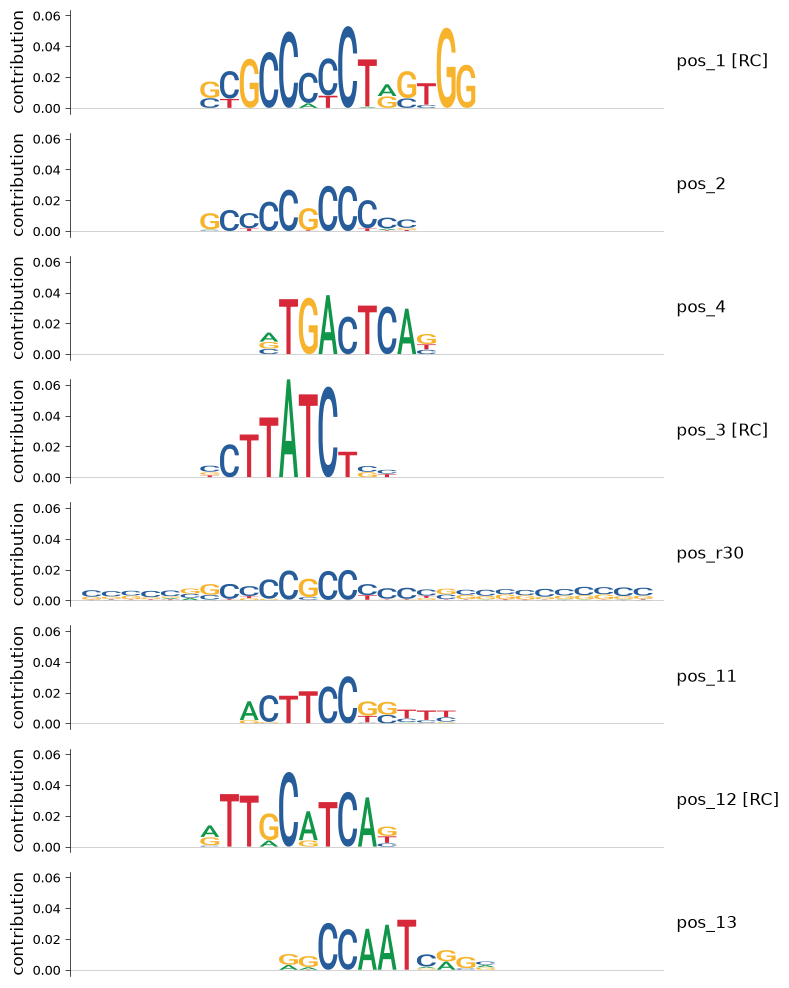

In [7]:
fig = um.view_motifs(found.cwms[:8], names_pos="right", show_positions=False, figsize=(8, 10))

## Naming the motifs

The model's TF-MoDISco patterns, read with
[`read_modisco()`][universalmotif.read_modisco], were found in all 270,000
regions rather than the 9,000 or so of chromosome 1 we used. We compare
the CWMs with those of the positive patterns, keeping the best match of
each, and name the patterns by their best JASPAR match as in the deep
learning guide:

In [8]:
def pattern_name(m):
    return m.replace(name=f"pattern_{m.name.rsplit('_', 1)[1]}")

modisco = [pattern_name(m) for m in um.read_modisco(modisco_path) if m.name.startswith("pos")]
cmp = um.compare_motifs(found.cwms + modisco, compare_to=list(range(len(found))), qvalue=1, nthreads=2)
best = (cmp.filter(pl.col("target_i") >= len(found)).sort("score", descending=True)
        .group_by("subject", maintain_order=True).first())

jaspar = um.read_meme(jaspar_path)
tf = {m.name: m.altname for m in jaspar}
ppms = [pattern_name(m) for m in um.read_modisco(modisco_path, type="PPM", trim_threshold=0.2)
        if m.name.startswith("pos")]
named = um.compare_motifs(ppms + jaspar, compare_to=list(range(len(ppms))), qvalue=0.05, complete=True, nthreads=2)
names = dict(named.filter(pl.col("target_i") >= len(ppms)).sort("qvalue").group_by("subject", maintain_order=True)
             .first().select("subject", tf=pl.col("target").replace_strict(tf)).iter_rows())
(
    found.motifs.select("name", "consensus", "seqlets")
    .join(best.select(name="subject", pattern="target", cosine="score"), on="name", how="left")
    .with_columns(tf=pl.col("pattern").replace_strict(names, default=None), cosine=pl.col("cosine").round(2))
)

name,consensus,seqlets,pattern,cosine,tf
str,str,i64,str,f64,str
"""pos_1""","""CCASYAGRKGGCRS""",2497,"""pattern_1""",1.0,"""CTCF"""
"""pos_2""","""GCYCCGCCCCY""",2245,"""pattern_2""",0.99,"""KLF16"""
"""pos_4""","""RTGACTCAB""",1442,"""pattern_3""",0.98,"""Bach1::Mafk"""
"""pos_3""","""RNAGATAAGR""",1027,"""pattern_0""",0.97,"""GATA2"""
"""pos_r30""","""CNSCNAGCYCCGCCTCCCNGSNNCNCNCC""",2201,"""pattern_2""",0.85,"""KLF16"""
"""pos_11""","""ACTTCCTSTTY""",722,"""pattern_8""",0.97,"""SPIB"""
"""pos_12""","""MTGATGCAAY""",437,"""pattern_7""",0.99,"""ATF4"""
"""pos_13""","""RGCCAATSRGA""",402,"""pattern_5""",0.98,"""NFYA"""
"""pos_r9""","""NYTGGCASNNRGCCARG""",430,"""pattern_11""",0.98,"""NFIC"""


Seventeen of the 29 motifs match one of the TF-MoDISco patterns with a
cosine of 0.9 or more, and between them they find 16 different patterns:
besides the four commonest, the CTCF site, the GC box of the SP and KLF
factors, the MAF recognition element of NF-E2 (named after its closest
JASPAR motif, BACH1::MAFK) and the GATA site, there are the sites of two
kinds of ETS factor, ATF4, NF-Y, NFI, NRF1, STAT, ZBTB33, an E box and
THAP11, the last a pattern 26 bases wide that our motif spans whole.
Several others are further spellings of the commonest patterns, such as
GC-rich motifs close to the GC box, which each reach seqlets the others
miss. `pos_49`, which holds `GGTTCGAWTCC`, is the B box of tRNA genes, a
promoter element of RNA polymerase III; TF-MoDISco reports it too, as
pattern 24, though our motif matches it less closely.

NFI, a palindrome of two half sites whose letters vary too much for any
one word of it to stand out, was found by the second search (`pos_r9`):
its sites are under 3% of the seqlets, but a larger share of those that
the first motifs left unreached. Composite motifs were searched for too,
but none added enough seqlets to be kept in these 21,000 windows; over
more of the model's regions, the composite of the TAL1 E box and the GATA
site, `CTG` then `WGATAA` 7 or 8 bases on, is.

## Choosing the settings

The defaults aim at finding the patterns a model has learned, and keep a
motif when it adds at least 0.25% of the seqlets, even if it is similar to
others in its letters, as long as its CWM differs. For a short list of
motifs that between them reach as many seqlets as possible, such as for
scanning new sequences, keep motifs that add at least 1% and drop the CWM
comparison:

In [9]:
short = um.contribution_motifs(scores, seqs, seed=1, nthreads=2, min_gain=0.01, max_similarity=None)
short.motifs.select("name", "consensus", "seqlets", "gain", "cumulative")

name,consensus,seqlets,gain,cumulative
str,str,i64,f64,f64
"""pos_1""","""CCASYAGRKGGCRS""",2528,0.154353,0.154353
"""pos_2""","""GCCCCGCCCCC""",2240,0.128587,0.282941
"""pos_r4""","""STGATAASR""",1425,0.086213,0.369154
"""pos_4""","""RTGACTCA""",1423,0.085175,0.454329
"""pos_3""","""RNAGATAAGN""",1381,0.042496,0.496825
"""pos_11""","""ACTTCCTSTTY""",719,0.039077,0.535902
"""pos_r2""","""GRCCACGCCCMC""",830,0.027903,0.563805
"""pos_12""","""MTGATGCAAY""",433,0.025095,0.5889
"""pos_13""","""RGCCAATSRGMR""",440,0.024973,0.613872


These 20 motifs reach 78% of the seqlets between them, against 71% for the
29 above, since motifs close to one another in their CWMs now stay, each
catching sites the others miss, while rarer motifs adding less than 1% of
the seqlets go.

Other options trade one thing for another:

- `stability=4` reruns each search on four random halves of the seqlets
  and keeps the motifs found again in at least three of them, which makes
  the motifs found in one set of regions more like those another set would
  give, at the cost of the rarest motifs, which half the seqlets may not
  hold often enough to be found.
- `hypothetical` takes the model's hypothetical scores, those of every
  letter at every position, and adds a second search on the seqlets
  rewritten in the letters the model prefers by
  [`idealize_sequences()`][universalmotif.idealize_sequences]. Degenerate
  sites, whose letters vary too much for any one word to be common, such as
  the spaced palindromes of NFI, are found more reliably this way, then
  rebuilt from the real sequences. The bigWig track holds only the scores of the bases
  present, so we cannot show it here; chromBPNet writes hypothetical scores
  to files that [`read_contributions()`][universalmotif.read_contributions]
  reads.
- `decoys` takes the model's scores for shuffled sequences, such as from
  [`shuffled_references()`][universalmotif.shuffled_references], for the
  seqlets' false discovery rate.
- `sign="both"` searches the negative seqlets too.
- `rounds=1` leaves out the second search, `gapped=False` the composites
  and `hits=False` the matching, each making the call quicker.

With a model at hand, the extra inputs come from the same functions as in
the deep learning guide. This code is not run here, and `model` and
`attribute` stand for a model and a function giving its contribution
scores for one-hot sequences, observed and hypothetical:

```python
x = um.one_hot(seqs)
observed, hypothetical = attribute(model, x)
decoys, _ = attribute(model, um.shuffled_references(x, n=1, seed=1)[:, 0])
found = um.contribution_motifs(observed, seqs, hypothetical=hypothetical, decoys=decoys)
```

## Step by step

`contribution_motifs()` is a shortcut through functions that can each be
called on their own, for more control over any step. The search on the
seqlets' letters, for example, is an ordinary call to `motif_finder()`, and
its motifs can be refined and selected with the seqlets as the sites they
should reach:

In [10]:
pos = seqlets.filter(pl.col("sign") == "+")
targets = [seqs[i][max(s - 3, 0):e + 3] for i, s, e in pos.select("sequence_i", "start", "end").iter_rows()]
plain = um.motif_finder(targets, nmotifs=20, seed=1, nthreads=2)
refined = um.refine_motifs(plain, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen = um.select_motifs(refined, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen.select("motif", "rank", "targets", "gain", "kept").head(10)

motif,rank,targets,gain,kept
str,u32,u64,f64,bool
"""motif_1""",1,2411,0.14721,true
"""motif_3""",2,2061,0.121504,true
"""motif_2""",3,1937,0.11723,true
"""motif_4""",4,1556,0.093296,true
"""motif_6""",5,703,0.03871,true
"""motif_7""",6,570,0.03291,true
"""motif_10""",7,507,0.027293,true
"""motif_8""",8,464,0.026255,true
"""motif_9""",9,440,0.025156,true


Here the background is three shuffles of the seqlets, the default when none
is given, where `contribution_motifs()` draws windows from the regions
away from any seqlet, which keeps the motifs common to all accessible
regions, such as their GC-rich stretches, from looking enriched.

## Matching the motifs to the scores

`contribution_motifs()` matched the CWMs against the scores with
[`scan_contributions()`][universalmotif.scan_contributions], which finds
the sites the model relied on rather than every site that looks like a
motif. A window is a hit when its similarity to the CWM and its
importance both reach the motif's thresholds, set so that 95% of the
motif's hits in the seqlets would pass each, as
[`modisco_thresholds()`][universalmotif.modisco_thresholds] sets them for
TF-MoDISco patterns:

In [11]:
print(found.hits.height, "hits in", len(seqs), "windows")
found.thresholds.head(8)

83641 hits in 21292 windows


motif,min_similarity,min_importance
str,f64,f64
"""pos_1""",0.806524,0.449229
"""pos_2""",0.843886,0.651154
"""pos_4""",0.909722,0.454551
"""pos_3""",0.943652,0.410695
"""pos_r30""",0.660534,1.572724
"""pos_11""",0.707448,0.666721
"""pos_12""",0.78162,0.453308
"""pos_13""",0.870663,0.634568


Every motif is matched on its own, so similar motifs can each have a hit
at one site. To see a single window, we match again with the same
thresholds, keeping only the best hit where those of different motifs
overlap, and look at the window with the most different motifs among the
first 3,000:

In [12]:
hits = um.scan_contributions(found.cwms, scores[:3000], sequences=seqs[:3000], thresholds=found.thresholds,
                             no_overlaps_across_motifs=True, nthreads=2)
row = int(hits.group_by("sequence_i").agg(pl.col("motif").n_unique().alias("n"))
          .sort("n", "sequence_i", descending=[True, False])["sequence_i"][0])
here = hits.filter(pl.col("sequence_i") == row)
here.select("motif", "start", "end", "strand", "match", "similarity", "importance")

motif,start,end,strand,match,similarity,importance
str,i64,i64,str,str,f64,f64
"""pos_4""",174,183,"""-""","""CTGACTCAT""",0.98283,0.32399
"""pos_17""",337,353,"""+""","""CAAGATGGCGAACACC""",0.9025,0.203618
"""pos_34""",270,282,"""-""","""ATCAGTTACGGC""",0.565825,0.141605
"""pos_43""",208,220,"""+""","""GGCCACGTGGCT""",0.88079,0.17672
"""pos_r31""",224,232,"""+""","""CTAACCCG""",0.53288,0.107838
"""pos_r31""",314,322,"""+""","""TACTGGCG""",0.541982,0.087345
"""pos_r34""",237,251,"""-""","""ACGTCACTTCTCCC""",0.848058,0.206503


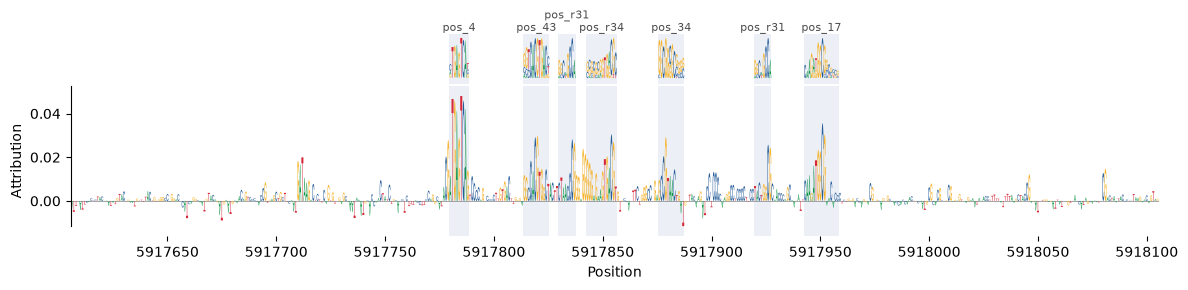

In [13]:
c, s, e = windows.row(row)
ax = um.view_attributions(scores[row], seqs[row], start=s, hits=here, motifs=found.cwms, figsize=(12, 3))